In [3]:
import os
import time
import requests
import pandas as pd

COUNTRIES = {
    "TUR": "Turkey",
    "EGY": "Egypt",
    "SAU": "Saudi Arabia",
    "NGA": "Nigeria",
    "KAZ": "Kazakhstan",
    "ZAF": "South Africa",
    "POL": "Poland",
}

INDICATORS = {
    "NY.GDP.MKTP.KD.ZG": "GDP growth (%)",
    "FP.CPI.TOTL.ZG": "Inflation (%)",
    "BN.CAB.XOKA.GD.ZS": "Current account (% GDP)",
    "FI.RES.TOTL.MO": "Reserves (months of imports)",
    "GC.DOD.TOTL.GD.ZS": "Govt debt (% GDP)",
    "GC.TAX.TOTL.GD.ZS": "Tax revenue (% GDP)",
}

CACHE_FILE = "ceemea_macro.csv"

def fetch_indicator(code):
    """Pull one indicator for all countries from the World Bank API."""
    url = f"https://api.worldbank.org/v2/country/{';'.join(COUNTRIES)}/indicator/{code}"
    params = {"format": "json", "date": "2015:2025", "per_page": 1000}
    resp = requests.get(url, params=params, timeout=60)
    resp.raise_for_status()
    payload = resp.json()
    if len(payload) < 2 or payload[1] is None:
        return pd.DataFrame()
    rows = [
        {
            "country": COUNTRIES.get(r["countryiso3code"], r["country"]["value"]),
            "year": int(r["date"]),
            "indicator": INDICATORS[code],
            "value": r["value"],
        }
        for r in payload[1]
    ]
    return pd.DataFrame(rows)

# Load anything saved earlier, so we only fetch what's missing
if os.path.exists(CACHE_FILE):
    data = pd.read_csv(CACHE_FILE)
else:
    data = pd.DataFrame(columns=["country", "year", "indicator", "value"])

for code, name in INDICATORS.items():
    if name in set(data["indicator"]):
        print(f"Already have: {name}")
        continue
    for attempt in range(3):
        try:
            df = fetch_indicator(code)
            if not df.empty:
                data = pd.concat([data, df], ignore_index=True)
                data.to_csv(CACHE_FILE, index=False)  # save after every success
                print(f"OK: {name}")
                break
        except Exception as e:
            print(f"Attempt {attempt + 1} failed for {name}: {e}")
        time.sleep(5)
    else:
        print(f"Still missing: {name}")

# Latest available year for each country + indicator
data = data.dropna(subset=["value"])
latest = data.sort_values("year").groupby(["country", "indicator"]).tail(1)
snapshot = latest.pivot(index="country", columns="indicator", values="value").round(1)
data_year = latest.pivot(index="country", columns="indicator", values="year")
display(snapshot)
display(data_year)

/tmp/ipykernel_2015/121071201.py:61: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data, df], ignore_index=True)


OK: GDP growth (%)
OK: Inflation (%)
OK: Current account (% GDP)
OK: Reserves (months of imports)
OK: Govt debt (% GDP)
OK: Tax revenue (% GDP)


indicator,Current account (% GDP),GDP growth (%),Govt debt (% GDP),Inflation (%),Reserves (months of imports),Tax revenue (% GDP)
country,,,,,,
Egypt,-3.8,4.4,NaN,14.1,4.4,12.5
Kazakhstan,-4.1,6.5,20.9,11.4,7.4,11.9
Nigeria,4.8,4.0,NaN,23.0,7.1,NaN
Poland,-1.0,3.6,NaN,3.8,5.9,17.4
Saudi Arabia,-2.6,4.5,NaN,2.0,15.6,8.1
South Africa,-0.4,1.1,82.8,3.2,6.2,25.9
Turkey,-1.9,3.6,25.5,34.9,5.1,17.6


indicator,Current account (% GDP),GDP growth (%),Govt debt (% GDP),Inflation (%),Reserves (months of imports),Tax revenue (% GDP)
country,,,,,,
Egypt,2025,2025,NaN,2025,2025,2015
Kazakhstan,2025,2025,2023,2025,2025,2023
Nigeria,2025,2025,NaN,2025,2025,NaN
Poland,2025,2025,NaN,2025,2025,2024
Saudi Arabia,2025,2025,NaN,2025,2025,2024
South Africa,2025,2025,2024,2025,2025,2024
Turkey,2025,2025,2024,2025,2025,2024


indicator,Current account (% GDP),GDP growth (%),Govt debt (% GDP),Inflation (%),Reserves (months of imports),Tax revenue (% GDP),Macro strength score,Indicators used
country,,,,,,,,
Saudi Arabia,-2.6,4.5,NaN,2.0,15.6,8.1,70.0,5
Kazakhstan,-4.1,6.5,20.9,11.4,7.4,11.9,66.0,6
Nigeria,4.8,4.0,NaN,23.0,7.1,NaN,64.0,4
South Africa,-0.4,1.1,82.8,3.2,6.2,25.9,63.0,6
Poland,-1.0,3.6,NaN,3.8,5.9,17.4,56.0,5
Turkey,-1.9,3.6,25.5,34.9,5.1,17.6,47.0,6
Egypt,-3.8,4.4,NaN,14.1,4.4,NaN,39.0,4


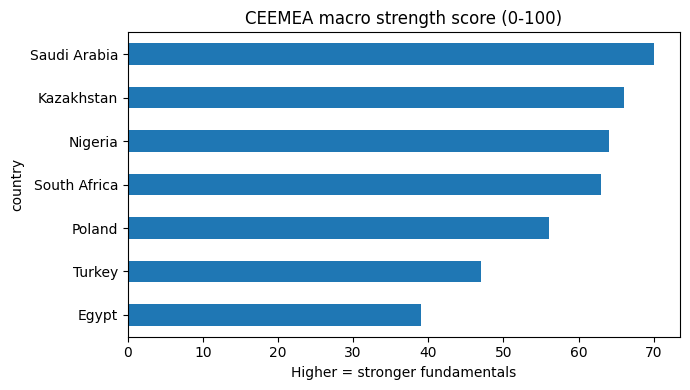

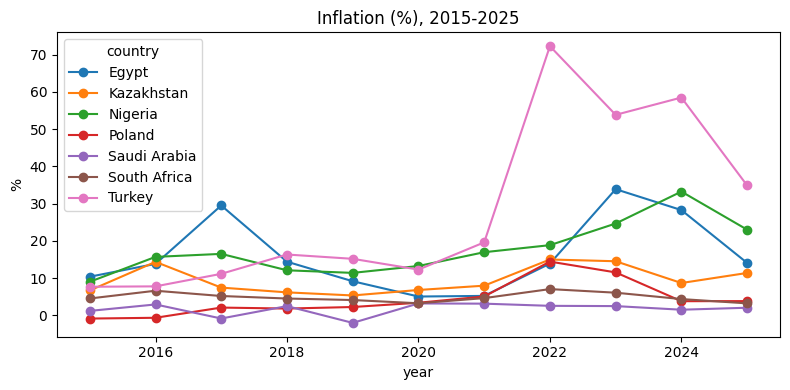

In [4]:
import matplotlib.pyplot as plt

# Ignore stale data: drop any value older than 2020
snapshot = snapshot.where(data_year >= 2020)

# +1 = higher is better, -1 = lower is better
DIRECTION = {
    "GDP growth (%)": 1,
    "Inflation (%)": -1,
    "Current account (% GDP)": 1,
    "Reserves (months of imports)": 1,
    "Govt debt (% GDP)": -1,
    "Tax revenue (% GDP)": 1,
}

# Score each indicator 0-100 by ranking countries against each other
scores = pd.DataFrame(index=snapshot.index)
for col, sign in DIRECTION.items():
    if col in snapshot:
        scores[col] = (snapshot[col] * sign).rank(pct=True) * 100

scorecard = snapshot.copy()
scorecard["Macro strength score"] = scores.mean(axis=1).round(0)
scorecard["Indicators used"] = scores.notna().sum(axis=1)
scorecard = scorecard.sort_values("Macro strength score", ascending=False)
display(scorecard)

# Chart 1: scorecard ranking
ax = scorecard["Macro strength score"].sort_values().plot(
    kind="barh", figsize=(7, 4), title="CEEMEA macro strength score (0-100)")
ax.set_xlabel("Higher = stronger fundamentals")
plt.tight_layout(); plt.savefig("scorecard.png", dpi=150); plt.show()

# Chart 2: inflation over time
infl = data[data["indicator"] == "Inflation (%)"].pivot(index="year", columns="country", values="value")
ax = infl.plot(figsize=(8, 4), marker="o", title="Inflation (%), 2015-2025")
ax.set_ylabel("%")
plt.tight_layout(); plt.savefig("inflation.png", dpi=150); plt.show()

In [7]:
%pip install -q anthropic feedparser

import urllib.parse
from datetime import date
import feedparser
import anthropic
from google.colab import userdata
from IPython.display import Markdown, display

client = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))

def get_headlines(country, n=8):
    """Latest economy/markets headlines for a country from Google News RSS."""
    q = urllib.parse.quote(f"{country} economy OR bonds OR central bank when:2d")
    url = f"https://news.google.com/rss/search?q={q}&hl=en-GB&gl=GB&ceid=GB:en"
    feed = feedparser.parse(url)
    return [f"- {e.title}" for e in feed.entries[:n]]

headlines = {c: get_headlines(c) for c in COUNTRIES.values()}

macro_context = scorecard.drop(columns=["Indicators used"]).to_string()
news_block = "\n\n".join(
    f"{c}:\n" + ("\n".join(h) if h else "- (no headlines)") for c, h in headlines.items()
)

prompt = f"""You are an analyst on an emerging markets sovereign debt team.
Write today's morning note for portfolio managers.

Latest macro snapshot (World Bank, most recent year available):
{macro_context}

Headlines from the last 48 hours:
{news_block}

Rules:
- Use only the headlines and data above. Do not add facts from memory.
- Open with a 2-line summary of the most important development across all countries.
- For each country: up to 2 bullets on what matters for sovereign credit, then one line
  starting "Bond/FX read:" giving your view, clearly framed as a judgement.
- If a country has no relevant headlines, write "No material news."
- Under 400 words. Plain, direct language."""

response = client.messages.create(
    model="claude-sonnet-5-5",
    max_tokens=4000,
    messages=[{"role": "user", "content": prompt}],
)
brief = "".join(block.text for block in response.content if block.type == "text")

display(Markdown(brief))
with open(f"brief_{date.today()}.md", "w") as f:
    f.write(brief)

**Morning Note: EM Sovereigns**

**Summary:** South Africa is the main market mover. The rand is at a seven-month low on coalition talks, and inflation has jumped to 5.2% just before the rate decision.
Poland's central bank has frozen the Constitutional Tribunal's accounts, a governance risk that is escalating.

**South Africa** (score 63)
- Headline inflation is 5.2%, up from 3.2% in the World Bank snapshot, ahead of the rate decision. A hold still looks likely.
- The rand is weak on post-local-election coalition talks. Debt at 82.8% of GDP and growth of 1.1% leave little room for policy noise.
- *Bond/FX read:* My judgement is that the rand stays under pressure until coalition clarity arrives, and a hawkish hold would limit upside for local bonds.

**Poland** (score 56)
- The central bank froze the Constitutional Tribunal's payments, and the government accuses it of politicisation. The dispute now involves the presidency too.
- Fundamentals are sound, with growth of 3.6% and reserves of 5.9 months. The risk is institutional, not macro.
- *Bond/FX read:* I see a modest governance premium, not a repricing, unless the dispute reaches the central bank's credibility on policy.

**Turkey** (score 47)
- The central bank raised its inflation targets and extended the disinflation timeline. Inflation was 34.9% in the snapshot. A prosecutor also wants to probe the former banking regulator chief.
- Households are strained by the gold-price slide. JPMorgan raised Turkey on recovery hopes.
- *Bond/FX read:* I think the slower disinflation path and governance headlines outweigh the upgrade. I would stay cautious on lira duration.

**Egypt** (score 39, lowest in the group)
- Suez Canal recovery is supporting FX inflows, and the EBRD lent $100m to National Bank of Egypt. Reserves of 4.4 months and inflation of 14.1% remain thin buffers.
- Bloomberg flags that African economies will end the year with high rates as Fed risks loom.
- *Bond/FX read:* In my view the inflow story is positive but unproven. I would stay neutral until reserves show sustained gains.

**Nigeria** (score 64)
- Governor Cardoso says NNPCL's operations are central to reserves and fiscal revenue. That points to oil-sector dependence.
- The current account is +4.8% of GDP, but inflation is 23.0%.
- *Bond/FX read:* My judgement is that the external position is supportive. Inflation and NNPCL transparency are the swing factors.

**Kazakhstan** (score 66)
- The IMF forecasts faster growth in 2027, and the government is promoting the Middle Corridor trade route.
- Debt is low at 20.9% of GDP. The weak points are inflation of 11.4% and a current account deficit of 4.1%.
- *Bond/FX read:* I see stable to positive credit with low fiscal risk. Inflation is the main watch item.

**Saudi Arabia** (score 70, highest)
- Fitch expects tighter bank liquidity in 2027 as funding demand rises, and loans are growing faster than deposits.
- Reserves are strong at 15.6 months, though the current account is -2.6%.
- *Bond/FX read:* I think sovereign credit is solid. Bank funding is a slow-moving sector risk, not a near-term sovereign one.

*Note: World Bank data is the latest annual figure and can lag current prints, as with South African inflation.*

,Macro score,S&P rating,Rating (numeric),Score rank,Rating rank,Gap
Saudi Arabia,70.0,A+,13,1,1,0
Poland,56.0,A-,11,5,2,3
Kazakhstan,66.0,BBB,9,2,3,-1
South Africa,63.0,BB,6,4,4,0
Turkey,47.0,BB-,5,6,5,1
Egypt,39.0,B,3,7,6,1
Nigeria,64.0,B,3,3,6,-3


Rank correlation with S&P ratings: 0.58 (p = 0.18, n = 7)


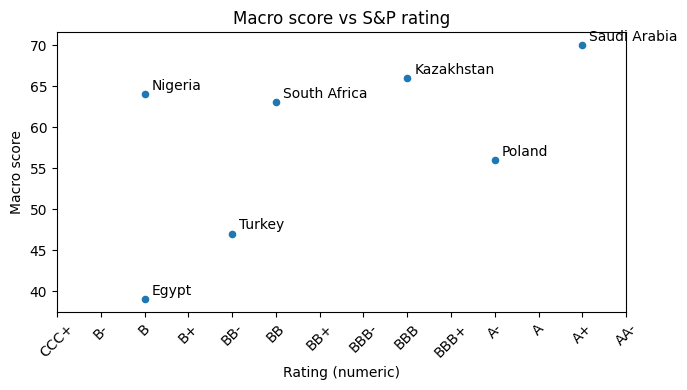

In [8]:
from scipy.stats import spearmanr

# S&P long-term foreign-currency sovereign ratings, as of 18 Nov 2026
SP_RATINGS = {
    "Saudi Arabia": "A+",
    "Poland": "A-",
    "Kazakhstan": "BBB",
    "South Africa": "BB",
    "Turkey": "BB-",
    "Egypt": "B",
    "Nigeria": "B",
}

# Convert letter grades to numbers (higher = better credit)
SCALE = ["CCC+", "B-", "B", "B+", "BB-", "BB", "BB+",
         "BBB-", "BBB", "BBB+", "A-", "A", "A+", "AA-"]
rating_num = {c: SCALE.index(r) + 1 for c, r in SP_RATINGS.items()}

test = pd.DataFrame({
    "Macro score": scorecard["Macro strength score"],
    "S&P rating": pd.Series(SP_RATINGS),
    "Rating (numeric)": pd.Series(rating_num),
})
test["Score rank"] = test["Macro score"].rank(ascending=False).astype(int)
test["Rating rank"] = test["Rating (numeric)"].rank(ascending=False, method="min").astype(int)
test["Gap"] = test["Score rank"] - test["Rating rank"]
display(test.sort_values("Rating rank"))

rho, p = spearmanr(test["Macro score"], test["Rating (numeric)"])
print(f"Rank correlation with S&P ratings: {rho:.2f} (p = {p:.2f}, n = {len(test)})")

# Chart: score vs rating
ax = test.plot.scatter(x="Rating (numeric)", y="Macro score", figsize=(7, 4),
                       title="Macro score vs S&P rating")
for c, row in test.iterrows():
    ax.annotate(c, (row["Rating (numeric)"], row["Macro score"]),
                textcoords="offset points", xytext=(5, 3))
ax.set_xticks(range(1, len(SCALE) + 1))
ax.set_xticklabels(SCALE, rotation=45)
plt.tight_layout(); plt.savefig("score_vs_rating.png", dpi=150); plt.show()

In [9]:
# Add GDP per capita: a core input in rating agency models
INDICATORS["NY.GDP.PCAP.CD"] = "GDP per capita (US$)"

for attempt in range(3):
    try:
        gdppc = fetch_indicator("NY.GDP.PCAP.CD")
        if not gdppc.empty:
            break
    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {e}")
    time.sleep(5)

gdppc = gdppc.dropna(subset=["value"])
latest_pc = gdppc.sort_values("year").groupby("country").tail(1).set_index("country")["value"]

# Rescore with the extra indicator
snapshot2 = snapshot.copy()
snapshot2["GDP per capita (US$)"] = latest_pc
DIRECTION2 = {**DIRECTION, "GDP per capita (US$)": 1}

scores2 = pd.DataFrame(index=snapshot2.index)
for col, sign in DIRECTION2.items():
    if col in snapshot2:
        scores2[col] = (snapshot2[col] * sign).rank(pct=True) * 100

test["Macro score v2"] = scores2.mean(axis=1).round(0)
rho2, p2 = spearmanr(test["Macro score v2"], test["Rating (numeric)"])

print(f"v1 correlation: {rho:.2f}  ->  v2 with GDP per capita: {rho2:.2f} (p = {p2:.2f})")
display(test[["S&P rating", "Macro score", "Macro score v2"]].sort_values("Macro score v2", ascending=False))

v1 correlation: 0.58  ->  v2 with GDP per capita: 0.90 (p = 0.01)


,S&P rating,Macro score,Macro score v2
Saudi Arabia,A+,70.0,75.0
Kazakhstan,BBB,66.0,65.0
Poland,A-,56.0,61.0
South Africa,BB,63.0,60.0
Nigeria,B,64.0,54.0
Turkey,BB-,47.0,51.0
Egypt,B,39.0,37.0


In [11]:
# IMF World Economic Outlook: general government gross debt (% of GDP)
url = f"https://www.imf.org/external/datamapper/api/v1/GGXWDG_NGDP/{'/'.join(COUNTRIES)}"
for attempt in range(3):
    try:
        resp = requests.get(url, timeout=60)
        resp.raise_for_status()
        break
    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {e}")
        time.sleep(5)

imf = resp.json()["values"]["GGXWDG_NGDP"]

# Latest year up to 2025 (the IMF series also contains forecasts beyond that)
imf_debt = {}
for iso, series in imf.items():
    if iso not in COUNTRIES:
        continue
    years = [int(y) for y in series if int(y) <= 2025]
    if years:
        y = max(years)
        imf_debt[COUNTRIES[iso]] = {"IMF govt debt (% GDP)": round(series[str(y)], 1), "Year": y}
imf_debt_df = pd.DataFrame(imf_debt).T
display(imf_debt_df)

# Rescore using IMF debt for every country (one consistent definition)
snapshot3 = snapshot2.copy()
snapshot3["Govt debt (% GDP)"] = imf_debt_df["IMF govt debt (% GDP)"].astype(float)

scores3 = pd.DataFrame(index=snapshot3.index)
for col, sign in DIRECTION2.items():
    if col in snapshot3:
        scores3[col] = (snapshot3[col] * sign).rank(pct=True) * 100

test["Macro score v3"] = scores3.mean(axis=1).round(0)
rho3, p3 = spearmanr(test["Macro score v3"], test["Rating (numeric)"])

print(f"v1: {rho:.2f}  ->  v2 (+GDP per capita): {rho2:.2f}  ->  v3 (+IMF debt): {rho3:.2f} (p = {p3:.2f})")
display(test[["S&P rating", "Macro score v2", "Macro score v3"]].sort_values("Macro score v3", ascending=False))

,IMF govt debt (% GDP),Year
Egypt,86.8,2025.0
Kazakhstan,24.3,2025.0
Nigeria,36.1,2025.0
Poland,59.7,2025.0
Saudi Arabia,31.8,2025.0
South Africa,78.4,2025.0
Turkey,23.7,2025.0


v1: 0.58  ->  v2 (+GDP per capita): 0.90  ->  v3 (+IMF debt): 0.91 (p = 0.00)


,S&P rating,Macro score v2,Macro score v3
Saudi Arabia,A+,75.0,74.0
Kazakhstan,BBB,65.0,63.0
Poland,A-,61.0,59.0
South Africa,BB,60.0,59.0
Nigeria,B,54.0,55.0
Turkey,BB-,51.0,55.0
Egypt,B,37.0,33.0


In [12]:
%pip install -q yfinance
import numpy as np
import yfinance as yf

# USD exchange rates (local currency per 1 USD)
FX = {
    "Turkey": "TRY=X", "Egypt": "EGP=X", "Saudi Arabia": "SAR=X",
    "Nigeria": "NGN=X", "Kazakhstan": "KZT=X",
    "South Africa": "ZAR=X", "Poland": "PLN=X",
}
px = yf.download(list(FX.values()), period="1y", progress=False)["Close"]
px = px.rename(columns={v: k for k, v in FX.items()}).ffill().bfill()

# Local currency performance vs USD (negative = currency weakened)
local_ccy = 1 / px
fx_change = (local_ccy.iloc[-1] / local_ccy.iloc[0] - 1) * 100
fx_vol = local_ccy.pct_change().std() * np.sqrt(252) * 100

market = pd.DataFrame({
    "S&P rating": test["S&P rating"],
    "Macro score v3": test["Macro score v3"],
    "FX change vs USD, 1y (%)": fx_change.round(1),
    "FX volatility, annualised (%)": fx_vol.round(1),
})
display(market.sort_values("Macro score v3", ascending=False))

rho_fx, p_fx = spearmanr(market["Macro score v3"], market["FX volatility, annualised (%)"])
print(f"Macro score vs FX volatility: {rho_fx:.2f} (p = {p_fx:.2f})")

/tmp/ipykernel_2015/1369557173.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  px = yf.download(list(FX.values()), period="1y", progress=False)["Close"]


,S&P rating,Macro score v3,"FX change vs USD, 1y (%)","FX volatility, annualised (%)"
Saudi Arabia,A+,74.0,-0.1,14.0
Kazakhstan,BBB,63.0,17.0,11.2
Poland,A-,59.0,-9.0,7.8
South Africa,BB,59.0,-0.2,11.8
Nigeria,B,55.0,7.0,5.4
Turkey,BB-,55.0,-16.1,1.5
Egypt,B,33.0,-12.5,11.2


Macro score vs FX volatility: 0.61 (p = 0.15)


In [13]:
print(local_ccy.pct_change().abs().max().mul(100).round(1).sort_values(ascending=False))

Ticker
Saudi Arabia    4.0
Egypt           3.8
Kazakhstan      3.4
South Africa    2.7
Poland          2.1
Nigeria         1.7
Turkey          0.5
dtype: float64
